# Car VS Bike Classification

## Project Overview

The Goal of this Project is to Build an Image Classification Model that Identifies Whether Image belongs to Cars or Bikes

This Project Use Car vs Bike Classification Dataset. For More Information [Click Here](https://www.kaggle.com/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset)

In this Project, We're Going to Explore the Following Approaches:
1. OpenCV: Stands for Open Computer Vision, Let Computers Understands what is in the Picture. For Example Edge Detection
2. Ultralytics YOLO: You Only Look Once ia an Object Detection Algorithm that identifies and localizes objects within an image in a single pass through the network.

The Objective is to Understand How YOLO and OpenCV works and their Implementation. We Also going to use our own Utility File to reduce Repetition and Length of Code. 

## Importing Libraries and Setting Up Environment

In [1]:
## Pytorch
import torch
from torch import nn
from torch.optim import SGD, AdamW
from torch.utils.data import DataLoader

## Torchvision
import torchvision
from torchvision.transforms import v2

## TorchSummary
from torchinfo import summary

## OpenCV
import cv2 

## YOLO
try:
    from ultralytics import YOLO ## YOLO
except:
    print("[INFO] Couldn't find ultralytics... installing it.")
    !pip install -U ultralytics
    from ultralytics import YOLO

torch.manual_seed(42)
yolo = YOLO("yolo26n-cls.pt") ## Yolo Classification weights , n represents tiny Yolo Model 
model = yolo.model

## Import Utility Function
from pytorch_utils import train_model, test_model, eval_model, accuracy_fn, create_datasets, create_dataloaders, fit_model, plot_history

## TimeIT
from timeit import default_timer as timer

## Plotting
import matplotlib.pyplot as plt

## Confusion Matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

## Classification Report
from ignite.engine import Engine
from ignite.metrics import ClassificationReport

## Random Flips for openCV
import random

import shutil
from pathlib import Path

## Device SetUp
device = "cuda" if torch.cuda.is_available() else "cpu"

## Checking Version
print(f"PyTorch version: {torch.__version__}\ntorchvision version: {torchvision.__version__}\nDevice: {device}")

model.info()             # one-line summary: layers, parameters, gradients, GFLOPs
print(model.yaml)  # the model config used to build the architecture

[INFO] Couldn't find ultralytics... installing it.
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 47.0/47.0 kB 616.9 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.1/99.1 kB 5.2 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch version: 2.11.0+cu128
torchvision version: 0.26.0+cu128
Device: cuda
YOLO26n-cls summary: 120 layers, 2,812,104 parameters, 0 gradients, 3.3 GFLOPs
{'nc': 1000, 'scales': {'n': [0.5, 0.25, 1024], 's': [0.5, 0.5, 1024], 'm': [0.5, 1.0, 512], 'l': [1.0, 1.0, 512], 'x': [1.0, 1.5, 512]}, 'backbone': [[-1, 1, 'Conv', [64, 3, 2]], [-1, 1, 'Conv', [128, 3, 2]], [-1, 2, 'C3k2', [256, False, 0.25]], [-1, 1, 'Conv', [2

## Data Augmentation and PreProcessing

Now we import our essential libraries, we're now going to setting up some Augmentations and Preprocessings. For Augmentations, we use V2 and for Preprocessing, OpenCV. 

In [2]:
## Train Augmentation using V2
train_transforms = v2.Compose([
    v2.ToImage(),
    v2.AugMix(
        severity=3, # Strength
        mixture_width=3, # Augment Chains
        chain_depth=-1, # Depth of Augment Chains
        alpha=1.0),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean= (0.485, 0.456, 0.406),
        std= (0.229, 0.224, 0.225)
    )
])

## Val and Test Augmentation using v2
val_transforms = v2.Compose([
    v2.ToImage(),
    v2.ToDtype(torch.float32, scale=True),
    v2.Normalize(
        mean= (0.485, 0.456, 0.406),
        std= (0.229, 0.224, 0.225)
    )
])

## Preprocessing using OpenCV

def cv2_loader(path):
    # Read one image from disk
    img = cv2.imread(path, cv2.IMREAD_COLOR)

    if img is None:
        raise RuntimeError(f"Failed to read image: {path}")
    ## Resize to 224x224 (H x W)
    img = cv2.resize(img, (224, 224), interpolation=cv2.INTER_AREA)
    
    # OpenCV BGR -> GRAY for Edge Detection
    img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    
    edges = cv2.Canny(img, 100, 200)
    edges = cv2.cvtColor(edges, cv2.COLOR_GRAY2RGB)
    return edges

## Load Images into Datasets

As we Know that our data is in files means for example :- In Train Folder there are two folders name Car and Bike and those folders contains a lot of images related to their folders. so we gonna convert this dataset into `torchvision.datasets` format With the help of `ImageFolder`. For More Information, Please Visit this [site](https://docs.pytorch.org/vision/main/generated/torchvision.datasets.ImageFolder.html)

We Already create our ImageFloder Setup and stores that setup in our Utility File and can be callable using `create_datasets()` Function. This Function Requires :-
1. Path of your Dataset
2. Loader, For Example our cv2_loader
3. split and Consists of 4 points: `train`, `val`, `test`, and `trainval`
4. traintransform or evaltransform. Based on What you requires use one . eval is for both val and test transforms. 

In [3]:
## First combine Train and val Data for Future Use
path1 = Path("/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/train")
path2 = Path("/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset/val")

output = Path("/kaggle/working/Car-Bike-Dataset/train")

for source in [path1, path2]:
    for file in source.rglob("*"):
        if not file.is_file():
            continue

        # Preserve the class folder structure
        relative_path = file.relative_to(source)
        destination = output / relative_path
        destination.parent.mkdir(parents=True, exist_ok=True)

        # Avoid overwriting files with identical paths
        if destination.exists():
            destination = destination.with_name(
                f"{source.parent.name}_{destination.name}"
            )

        shutil.copy2(file, destination)

print("Saved to:", output)

Saved to: /kaggle/working/Car-Bike-Dataset/train


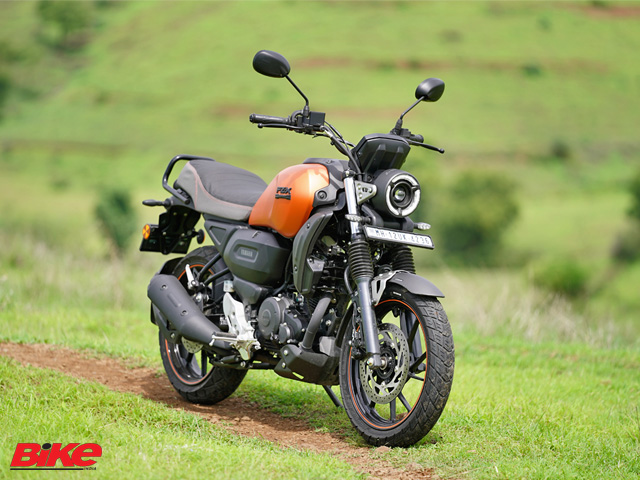

In [4]:
## Check one of the image from one of the combined images 
from PIL import Image
Image.open("/kaggle/working/Car-Bike-Dataset/train/Bike/Bike (1).jpg")

In [5]:
## Setup Path of Our Dataset
PATH = Path("/kaggle/input/datasets/utkarshsaxenadn/car-vs-bike-classification-dataset/Car-Bike-Dataset")
TrainVal = Path("/kaggle/working/Car-Bike-Dataset")

## Load Train_data
train_data = create_datasets(
    path=PATH,
    split="train",
    loader=cv2_loader,
    train_transform=train_transforms
)

## Load val_data
val_data = create_datasets(
    path=PATH,
    split="val",
    loader=cv2_loader,
    eval_transform=val_transforms
)

## Load Test_data
test_data = create_datasets(
    path=PATH,
    split="test",
    loader=cv2_loader,
    eval_transform=val_transforms
)

trainval_data = create_datasets(
    path=TrainVal,
    split="train",
    loader=cv2_loader,
    train_transform=train_transforms,
    eval_transform=train_transforms
)

## Length of all three datasets + total length of datasets
len(train_data), len(val_data), len(test_data), len(train_data)+len(val_data)+len(test_data), len(trainval_data)

(2800, 600, 600, 4000, 3400)

## Understanding Data

Let's Understand data and check the following thing :-
1. Classes
2. Image and it's type
3. labels
4. Shape of the Image

In [6]:
## Classes
class_names = train_data.classes
class_names

['Bike', 'Car']

As per classes, our Classification is going to be Binary Classification

In [7]:
## Load Image and Label of any random image from train Data

image, label = train_data[50]
image, class_names[label]

(Image([[[-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         ...,
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179],
         [-2.1179, -2.1179, -2.1179,  ..., -2.1179, -2.1179, -2.1179]],
 
        [[-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         ...,
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357],
         [-2.0357, -2.0357, -2.0357,  ..., -2.0357, -2.0357, -2.0357]],
 
        [[-1.8044, -1.8044, -1.8044,  ..., -1.8044, -1.8044, -1.8044],
         [-1.8044, -1.8044, -1.8044,  ..., 

In [8]:
## Type of our Image
type(image)

torchvision.tv_tensors._image.Image

In [9]:
## Shape of Image
image.shape

torch.Size([3, 224, 224])

tv_tensor Stands for TorchVision Tensor

## Creating DataLoaders

Now Let's Create Dataloaders. DataLoaders are the part of `torch.utils.data`. For More Information Click [Here](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html). We're Using Our custom `create_dataloaders()` utility Function to Create DataLoaders Easily

In [10]:
torch.manual_seed(42)
train_dataloader, val_dataloader, test_dataloader = create_dataloaders(train_data, 
                                                                       val_data, 
                                                                       test_data, 
                                                                       batch_size=32, 
                                                                       num_workers=3)

train_dataloader: 88 batches of 32
val_dataloader: 19 batches of 32
test_dataloader: 19 batches of 32


## Preparing Yolo Model

Now it's time to prepare our YOLO Model. To Prepare Yolo Model we need to do the following things :-
1. Freeze Layers(Optional)
2. Change/Replace The Final Layer of YOLO Model

Freezing is Completely Optional as it doesn't affect the results but this can reduce Memory Consumption.

Replacing Final Layer is Mandatory because the original final layer was built for a different task, a different number of output classes, and a specific source dataset

### Freezing Layers

In [11]:
## Creating Variable
freeze_layers = 6

## Loop for Freeze Layers
for i in range(freeze_layers):
    for param in model.model[i].parameters():
        param.requires_grad = False

# Verify how many parameters remain trainable
for name, param in model.named_parameters():
    print(name, param.requires_grad)

model.0.conv.weight False
model.0.bn.weight False
model.0.bn.bias False
model.1.conv.weight False
model.1.bn.weight False
model.1.bn.bias False
model.2.cv1.conv.weight False
model.2.cv1.bn.weight False
model.2.cv1.bn.bias False
model.2.cv2.conv.weight False
model.2.cv2.bn.weight False
model.2.cv2.bn.bias False
model.2.m.0.cv1.conv.weight False
model.2.m.0.cv1.bn.weight False
model.2.m.0.cv1.bn.bias False
model.2.m.0.cv2.conv.weight False
model.2.m.0.cv2.bn.weight False
model.2.m.0.cv2.bn.bias False
model.3.conv.weight False
model.3.bn.weight False
model.3.bn.bias False
model.4.cv1.conv.weight False
model.4.cv1.bn.weight False
model.4.cv1.bn.bias False
model.4.cv2.conv.weight False
model.4.cv2.bn.weight False
model.4.cv2.bn.bias False
model.4.m.0.cv1.conv.weight False
model.4.m.0.cv1.bn.weight False
model.4.m.0.cv1.bn.bias False
model.4.m.0.cv2.conv.weight False
model.4.m.0.cv2.bn.weight False
model.4.m.0.cv2.bn.bias False
model.5.conv.weight False
model.5.bn.weight False
model.5.bn.bia

In [12]:
## Checking Classifier (Checking Last layer of YOLO Model)
head = model.model[-1]
head, print("Original output classes:", head.linear.out_features)

Original output classes: 1000


(Classify(
   (conv): Conv(
     (conv): Conv2d(256, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
     (bn): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
     (act): SiLU(inplace=True)
   )
   (pool): AdaptiveAvgPool2d(output_size=1)
   (drop): Dropout(p=0.0, inplace=True)
   (linear): Linear(in_features=1280, out_features=1000, bias=True)
 ),
 None)

### Replacing Final Layer of Yolo Model

In [13]:
## Replacing
head.linear = nn.Linear(head.linear.in_features, len(class_names))

## Changing Device of Model
model = model.to(device)

print("Updated output classes:", head.linear.out_features)

Updated output classes: 2


In [14]:
## Checking Head Again
model.model[-1]

Classify(
  (conv): Conv(
    (conv): Conv2d(256, 1280, kernel_size=(1, 1), stride=(1, 1), bias=False)
    (bn): BatchNorm2d(1280, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (act): SiLU(inplace=True)
  )
  (pool): AdaptiveAvgPool2d(output_size=1)
  (drop): Dropout(p=0.0, inplace=True)
  (linear): Linear(in_features=1280, out_features=2, bias=True)
)

## Summary Of Model

Let's Summarize the model to verify the architecture, track trainable parameters, and debug dimensional mismatches before starting the training process

In [15]:
## Summary of Our Model
summary(model, 
        input_size=(32, 3, 224, 224), # make sure this is "input_size", not "input_shape" (batch_size, color_channels, height, width)
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"]
)

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
ClassificationModel (ClassificationModel)                    [32, 3, 224, 224]    [32, 2]              --                   Partial
├─Sequential (model)                                         --                   --                   --                   Partial
│    └─Conv (0)                                              [32, 3, 224, 224]    [32, 16, 112, 112]   --                   False
│    │    └─Conv2d (conv)                                    [32, 3, 224, 224]    [32, 16, 112, 112]   (432)                False
│    │    └─BatchNorm2d (bn)                                 [32, 16, 112, 112]   [32, 16, 112, 112]   (32)                 False
│    │    └─SiLU (act)                                       [32, 16, 112, 112]   [32, 16, 112, 112]   --                   --
│    └─Conv (1)                                              [32, 16, 112, 112]   [32

In [16]:
## Let's check some Parameters
model.named_parameters

<bound method Module.named_parameters of ClassificationModel(
  (model): Sequential(
    (0): Conv(
      (conv): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (1): Conv(
      (conv): Conv2d(16, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (act): SiLU(inplace=True)
    )
    (2): C3k2(
      (cv1): Conv(
        (conv): Conv2d(32, 32, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act): SiLU(inplace=True)
      )
      (cv2): Conv(
        (conv): Conv2d(48, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (bn): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
   

## Creating Loss Function and Optimizer With TimeIT

We're Creating Loss Fn, Optimizer and TimeIT Fn to :-

1. `TimeIT FN` to Check Time Consumption of Our Model
2. `Loss Fn` to calculates how wrong the model's predictions are compared to the true answers.
3. `Optimizer` to updates the model's weights to minimize that error and make the predictions more accurate.

In [17]:
def print_train_time(
    start: float,
    end: float,
    device: torch.device= None
):
    total_time = end - start
    print(f"Time Taken on {device} device is {total_time:.3f} seconds")

In [18]:
## Loss Function
loss_fn = nn.CrossEntropyLoss()

## Optimizer
optimizer = AdamW(
    lr= 1e-4,
    params= model.parameters()
)

## Training And Val Loop

We're Now Train Our YOLO Model with Train Data and Evaluate With Validate Data.

In [19]:
## Using pytorch_utils fit_model method to train our loop
history, best_model_state = fit_model(model=model,
                                      train_model=train_model,
                                      test_model=test_model,
                                      train_dataloader=train_dataloader,
                                      test_dataloader=val_dataloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      accuracy_fn=accuracy_fn,
                                      epochs=20,
                                      device=device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1
----------


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss = 0.52263 || Train Accuracy = 77.63%
Test loss: 0.35041 | Test accuracy: 92.27%

🔥 New best model! Accuracy: 92.27%
Epoch 2
----------


  0%|          | 0/88 [00:00<?, ?it/s]

...

Train Loss = 0.15212 || Train Accuracy = 94.28%
Test loss: 0.11531 | Test accuracy: 94.57%

Epoch 19
----------


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss = 0.16311 || Train Accuracy = 93.61%
Test loss: 0.10589 | Test accuracy: 96.66%

🔥 New best model! Accuracy: 96.66%
Epoch 20
----------


  0%|          | 0/88 [00:00<?, ?it/s]

Train Loss = 0.15549 || Train Accuracy = 93.89%
Test loss: 0.10757 | Test accuracy: 96.16%

Time Taken on cuda device is 342.253 seconds


## Plotting Curves of Train and Val Loop's Accuracy And Loss

This is to check our model Results Clearly

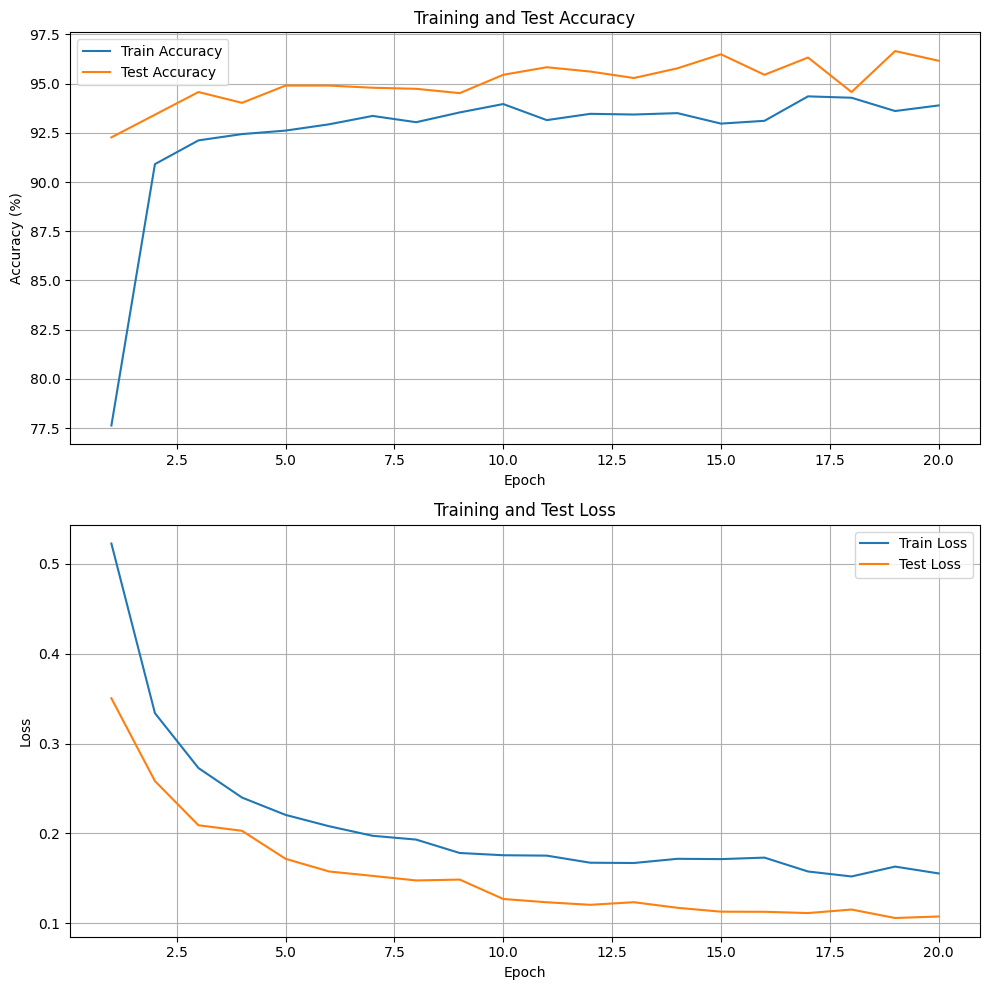

In [20]:
plot_history(history)

## Loading Best Epoch Model and Model Evaluation

during Train Loop, we are saving the best Epoch Loop to better usabilty to save the model and for Proper Evaluation

In [21]:
model.load_state_dict(best_model_state)

<All keys matched successfully>

In [22]:
evaluation = eval_model(model = model, 
               data_loader = val_dataloader, 
               loss_fn = loss_fn, 
               accuracy_fn = accuracy_fn,
              device = device)

evaluation

{'model_name': 'ClassificationModel',
 'model_loss': 0.10589280959806945,
 'model_acc': 96.65570175438596}

## Building Confusion Matrix

Building Confusion Matrix to Check What Our Model Predicts during Training

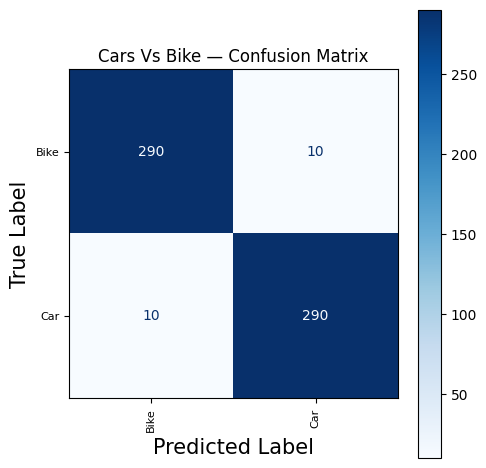

In [23]:
all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for x, y in val_dataloader:
        x = x.to(device)
        preds = model(x)[1].argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(5, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "Cars Vs Bike — Confusion Matrix",
)

ax.set_xlabel("Predicted Label", fontsize=15)
ax.set_ylabel("True Label", fontsize=15)

# Smaller class-name font
plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center",
    fontsize=8
)

plt.setp(
    ax.get_yticklabels(),
    fontsize=8
)

plt.tight_layout()
plt.show()

## Classification Report

Report For Checking Precision, Recall and F1 Score of our model that also Includes `Macro Avg`. 

Macro Avg calculates a metric (like precision, recall, or F1-score) by computing the score for each individual class independently and then taking the unweighted mean of those scores. Because it treats every class equally regardless of how many samples it contains, macro AVG is highly sensitive to the performance of minority/rare classes. 

In [24]:
# 1. Define an evaluation step function for the Ignite Engine
def evaluate_step(engine, batch):
    model.eval()
    with torch.no_grad():
        x, y = batch
        x, y = x.to(device), y.to(device)
        output = model(x)
        y_pred = output[1] if isinstance(output, tuple) else output
        return y_pred, y

evaluator = Engine(evaluate_step)

# 2. Attach the metric handler to your engine
# target_names is an optional list of string labels
cr = ClassificationReport(labels=class_names)
cr.attach(evaluator, "classification_report")

# 3. Run evaluation over your PyTorch DataLoader
state = evaluator.run(val_dataloader)

# 4. Extract and print results
state.metrics["classification_report"]

'{"Bike": {"precision": 0.9666666666666667, "recall": 0.9666666666666667, "f1-score": 0.9666666666666661}, "Car": {"precision": 0.9666666666666667, "recall": 0.9666666666666667, "f1-score": 0.9666666666666661}, "macro avg": {"precision": 0.9666666666666667, "recall": 0.9666666666666667, "f1-score": 0.9666666666666661}}'

After a Lot of Experiments and Collecting 6 Versions like infinity Stones, I got this Version Best with the Cap of 0.9666 in Macro_avg. (**Note**: Because Of Some Issues, Results Changes Everyday. Most Probably the Cuase of this problem is Related to GPU/CPU or Some Missing Seeds.)

Now, We're going to Complete Our model Fully by Combining Train Data and Validation Data and Evaluate Using Test Data. Since Our Test data is Already Prepared, We prepare Train + Val Data.

## Final Training on Train + Validation Data

Since We Already have `trainval_data` we just need to turn them into batches, create optimizer and train our model. But First Check Our Data.

In [25]:
image, label = trainval_data[3000]
image, class_names[label], type(image)

(Image([[[-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         ...,
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008]],
 
        [[-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         ...,
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182]],
 
        [[-1.7870, -1.7870, -1.7870,  ..., -1.7870, -1.7870, -1.7870],
         [-1.7870, -1.7870, -1.7870,  ..., 

## Create DataLoader for trainval Data

In [26]:
torch.manual_seed(42)
trainval_dataloader,_, _= create_dataloaders(trainval_data,  
                                     batch_size=32, 
                                     num_workers=3)

train_dataloader: 107 batches of 32


In [27]:
batch1 = next(iter(train_dataloader))
batch2 = next(iter(trainval_dataloader))

len(batch1), len(batch2)

(2, 2)

In [28]:
image, label

(Image([[[-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         ...,
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008],
         [-2.1008, -2.1008, -2.1008,  ..., -2.1008, -2.1008, -2.1008]],
 
        [[-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         ...,
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182],
         [-2.0182, -2.0182, -2.0182,  ..., -2.0182, -2.0182, -2.0182]],
 
        [[-1.7870, -1.7870, -1.7870,  ..., -1.7870, -1.7870, -1.7870],
         [-1.7870, -1.7870, -1.7870,  ..., 

## Create Loss Function and Optimizer

In [29]:
## Loss Function
loss_fn = nn.CrossEntropyLoss()

## Optimizer
optimizer = AdamW(
    lr= 1e-4,
    params= model.parameters()
)

## Train Model and Plotting curves

We're Training Model with train+val Data Combined and evaluate Using Test Data and Checking Model Performance By Plotting Curves

In [30]:
## Using pytorch_utils fit_model method to train our loop
history, best_model_state = fit_model(model=model,
                                      train_model=train_model,
                                      test_model=test_model,
                                      train_dataloader=trainval_dataloader,
                                      test_dataloader=test_dataloader,
                                      loss_fn=loss_fn,
                                      optimizer=optimizer,
                                      accuracy_fn=accuracy_fn,
                                      epochs=20,
                                      device=device)

  0%|          | 0/20 [00:00<?, ?it/s]

Epoch 1
----------


  0%|          | 0/107 [00:00<?, ?it/s]

Train Loss = 0.15350 || Train Accuracy = 93.84%
Test loss: 0.10588 | Test accuracy: 96.98%

🔥 New best model! Accuracy: 96.98%
Epoch 2
----------


  0%|          | 0/107 [00:00<?, ?it/s]

...

Train Loss = 0.12284 || Train Accuracy = 95.59%
Test loss: 0.09027 | Test accuracy: 96.98%

Epoch 19
----------


  0%|          | 0/107 [00:00<?, ?it/s]

Train Loss = 0.12708 || Train Accuracy = 95.36%
Test loss: 0.08896 | Test accuracy: 97.31%

🔥 New best model! Accuracy: 97.31%
Epoch 20
----------


  0%|          | 0/107 [00:00<?, ?it/s]

Train Loss = 0.13236 || Train Accuracy = 95.27%
Test loss: 0.09318 | Test accuracy: 96.82%

Time Taken on cuda device is 381.290 seconds


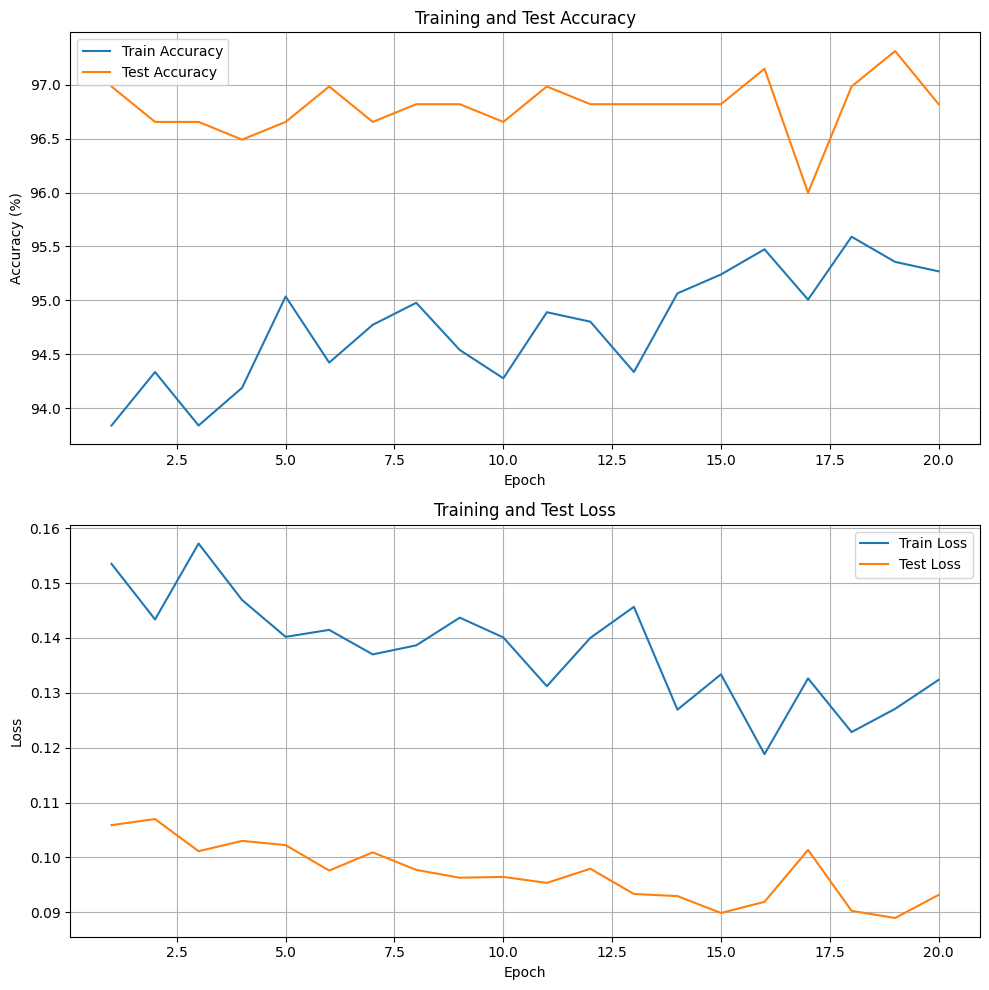

In [31]:
## Plotting History
plot_history(history)

## Final Model Evaluation, Confusion Matrix and Classification Report

In [32]:
model.load_state_dict(best_model_state)

evaluation = eval_model(model = model, 
               data_loader = test_dataloader, 
               loss_fn = loss_fn, 
               accuracy_fn = accuracy_fn,
              device = device)

evaluation

{'model_name': 'ClassificationModel',
 'model_loss': 0.08896498264450776,
 'model_acc': 97.31359649122807}

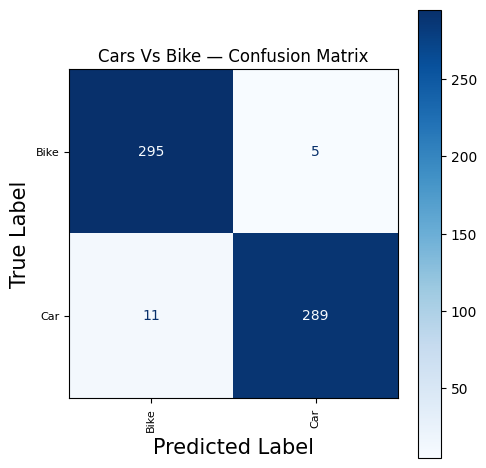

In [33]:
## Confusion Matrix
all_preds, all_labels = [], []

model.eval()
with torch.no_grad():
    for x, y in test_dataloader:
        x = x.to(device)
        preds = model(x)[1].argmax(dim=1).cpu()
        all_preds.append(preds)
        all_labels.append(y)

all_preds = torch.cat(all_preds).numpy()
all_labels = torch.cat(all_labels).numpy()

cm = confusion_matrix(all_labels, all_preds)

fig, ax = plt.subplots(figsize=(5, 5))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=True
)

ax.set_title(
    "Cars Vs Bike — Confusion Matrix",
)

ax.set_xlabel("Predicted Label", fontsize=15)
ax.set_ylabel("True Label", fontsize=15)

# Smaller class-name font
plt.setp(
    ax.get_xticklabels(),
    rotation=90,
    ha="center",
    fontsize=8
)

plt.setp(
    ax.get_yticklabels(),
    fontsize=8
)

plt.tight_layout()
plt.show()

In [34]:
# 1. Define an evaluation step function for the Ignite Engine
def evaluate_step(engine, batch):
    model.eval()
    with torch.no_grad():
        x, y = batch
        x, y = x.to(device), y.to(device)
        output = model(x)
        y_pred = output[1] if isinstance(output, tuple) else output
        return y_pred, y

evaluator = Engine(evaluate_step)

# 2. Attach the metric handler to your engine
# target_names is an optional list of string labels
cr = ClassificationReport(labels=class_names)
cr.attach(evaluator, "classification_report")

# 3. Run evaluation over your PyTorch DataLoader
state = evaluator.run(test_dataloader)

# 4. Extract and print results
state.metrics["classification_report"]

'{"Bike": {"precision": 0.9640522875816994, "recall": 0.9833333333333333, "f1-score": 0.973597359735973}, "Car": {"precision": 0.9829931972789115, "recall": 0.9633333333333334, "f1-score": 0.9730639730639726}, "macro avg": {"precision": 0.9735227424303055, "recall": 0.9733333333333334, "f1-score": 0.9733306663999728}}'

## Saving the Model

Now it's time to Save the model

In [35]:
## Using torch.save()
torch.save(best_model_state, 'yolo_custom_carbike.pt')
print("Model Saved Successfully")

Model Saved Successfully
